# Baseline pipeline: from raw fire detections to a tested model

**What this answers:** How good is the baseline at predicting that a new fire starts in a forest cell on the next day, and does it overfit?

**Order:** (1) the raw data and how rows and labels are made, (2) the model inputs at both levels, (3) how the one best setting per model was chosen, (4) the logistic baseline, boosting and the PyTorch network refitted with the official code, (5) the official results, (6) training versus validation versus test.

**Tools:** pandas, scikit-learn, PyTorch, matplotlib. Every code cell calls a library function in `wildfire.reporting.baseline_walkthrough`; the logic is in `src/`, not in the notebook.

**This notebook follows the official setup.** It uses the enriched level (251 inputs), the official fit set of the fold (all complete rows of the years before the test year, thinned to the official 2,000,000-row cap), the official design weights, the prior-shift correction, the official model classes and the official metric functions. The test-year numbers are read from the saved rolling-origin predictions; the models are refitted only to obtain training-set predictions and loss curves, and section 6 checks that the refit reproduces the saved predictions.

**What is NOT official** (and is labelled "not official" where it appears): accuracy, precision, recall, F1 and the decision threshold; the training-set metrics; the per-epoch network history; the confusion matrices; the block permutation importance. They use the official design weights. The network rows in the train / validation / test comparison are seed 0; the official tables average 10 seeds.

**Years:** development years only (fit up to 2023, test 2024 January-July; the threshold comes from the 2023 fold). 2025, the fresh states and the 2026 season are never loaded. 2024 helped choose the settings, so it is a fair check but not an untouched one. Nothing is written to `artifacts/results`.

In [1]:
from IPython.display import display
from wildfire.reporting import baseline_walkthrough as bw
w = bw.Walkthrough()

## Architecture and parameters of the baseline

A data flow that builds labelled rows, a ladder of seven models, and a fixed evaluation protocol. The figures are drawn by `docs/figures/draw_architecture.py`.

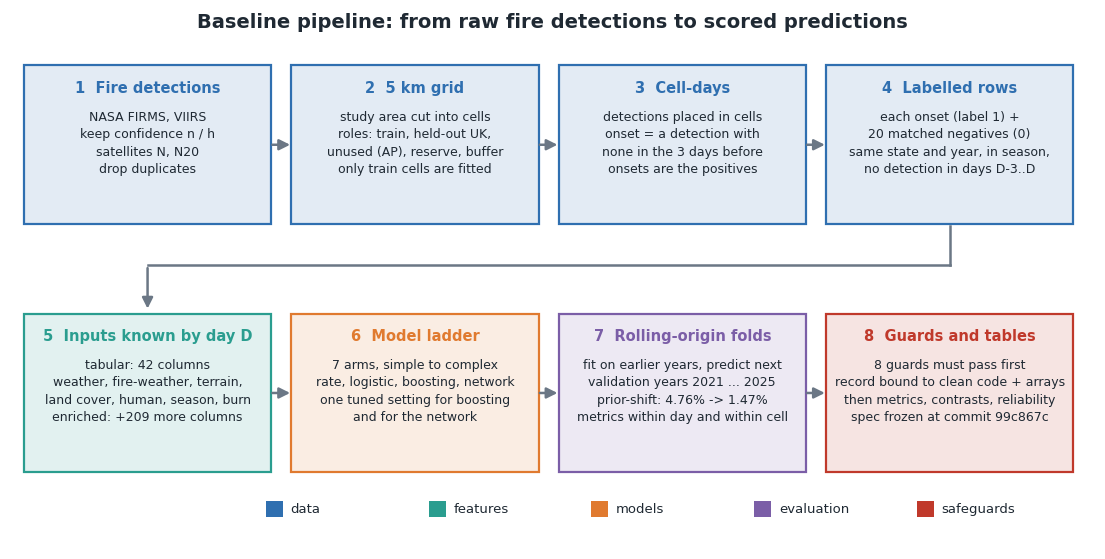

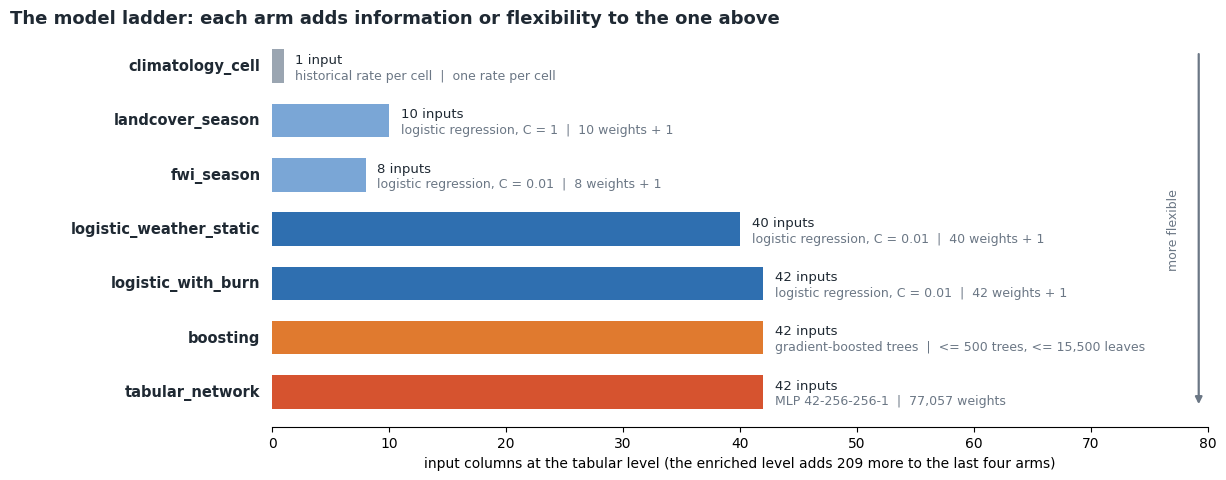

In [2]:
bw.architecture("plot_pipeline")
bw.architecture("plot_ladder")

| Arm | Model | Tabular inputs | Fitted parameters |
|---|---|---|---|
| climatology_cell | historical fire rate of each cell | 1 | one rate per cell |
| landcover_season | logistic regression, C = 1 | 10 | 10 weights + intercept |
| fwi_season | logistic regression, C = 0.01 | 8 | 8 weights + intercept |
| logistic_weather_static | logistic regression, C = 0.01 | 40 | 40 weights + intercept |
| logistic_with_burn | logistic regression, C = 0.01 | 42 | 42 weights + intercept |
| boosting | histogram gradient-boosted trees | 42 | up to 500 trees, at most 15,500 leaves |
| tabular_network | multilayer perceptron | 42 | 77,057 weights |

The last four arms also run at the enriched level (251 inputs = 42 tabular + 180 weather windows + 17 anomalies + 12 neighbourhood).

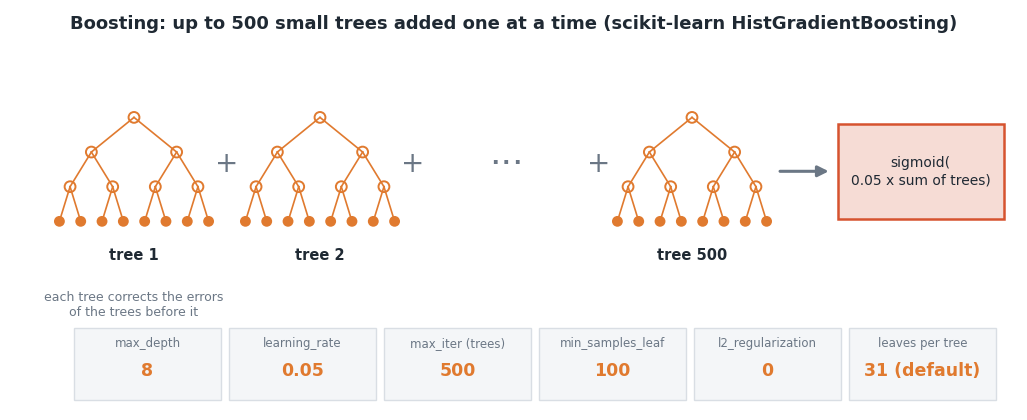

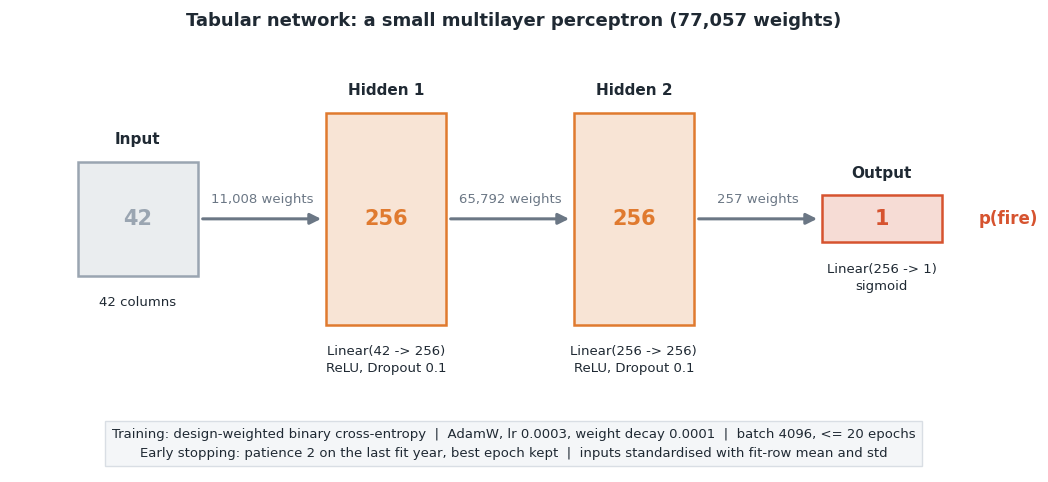

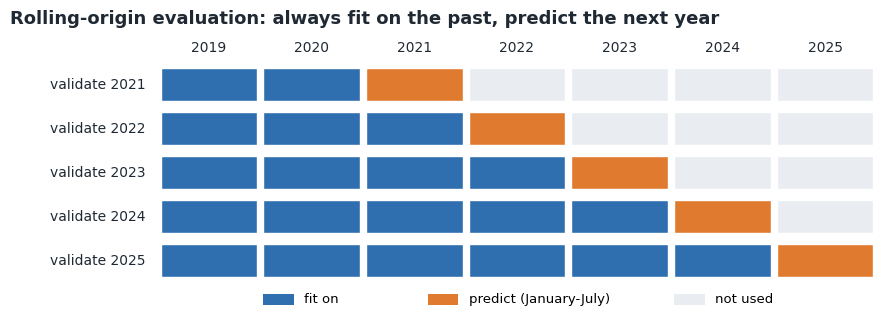

In [3]:
bw.architecture("plot_boosting")
bw.architecture("plot_network")
bw.architecture("plot_folds")

Tuning is a 12-trial random search per model on the rolling folds 2021-2024; the lowest mean validation log loss wins and 2025 takes no part. Chosen: **boosting** max_depth 8, learning_rate 0.05, 500 trees, min_samples_leaf 100, no L2; **network** width 256, depth 2, dropout 0.1, learning_rate 0.0003, weight_decay 0.0001. Network weights: 11,008 + 65,792 + 257 = 77,057.

## 1. Data extraction

**Raw fire detections (NASA FIRMS, VIIRS satellites).** One file holds five days of detections for a box over India. This is the label source.

In [4]:
raw = bw.raw_detections()
display(raw.head())

2158 VIIRS files; first: VIIRS_NOAA20_SP_2018-04-01.csv | last: VIIRS_SNPP_SP_south_2025-12-30.csv


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,13.82675,79.85177,331.50,0.77,0.77,2019-04-01,701,N20,VIIRS,l,2,303.59,8.11,D,0
1,13.82828,79.85869,343.75,0.77,0.77,2019-04-01,701,N20,VIIRS,n,2,302.73,9.00,D,0
2,13.82995,79.85577,356.05,0.77,0.77,2019-04-01,701,N20,VIIRS,n,2,303.99,10.79,D,0
3,13.86169,80.04298,330.46,0.74,0.76,2019-04-01,701,N20,VIIRS,n,2,300.07,3.73,D,0
4,8.00365,79.95535,332.31,0.43,0.62,2019-04-01,840,N20,VIIRS,n,2,298.96,2.54,D,0


**Filters.** Keep nominal and high confidence detections from the two kept satellites, and drop duplicates: the exact rule the pipeline applies.

In [5]:
bw.filter_summary(raw)

one file: 2,064 detections -> 1,526 after filters (74% kept)
confidence kept: ['n', 'h'] | satellites kept: ['N', 'N20']


**The grid.** The study area is cut into 5 km cells. Each cell has a role; only `train` cells are used to fit models.

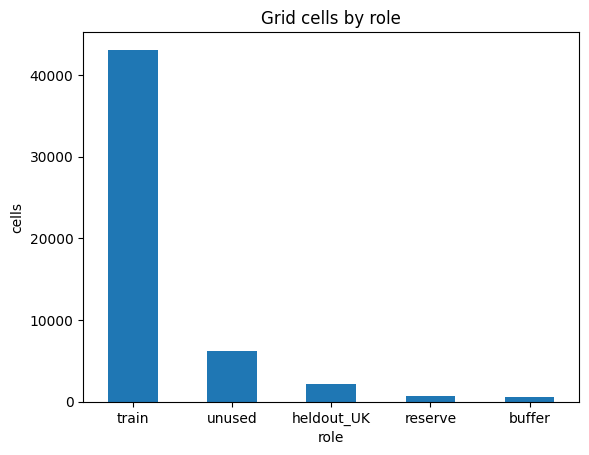

,cell,ix,iy,cx,cy,state,lon,lat,reserve,buffer_only,role,district
0,0,0,205,7012500.0,2482500.0,MH,72.678727,19.843731,NaN,False,train,Palghar
1,1,0,207,7012500.0,2492500.0,MH,72.678727,19.926959,NaN,False,train,Palghar
2,2,1,198,7017500.0,2447500.0,MH,72.730548,19.552769,NaN,False,train,Palghar
3,3,1,199,7017500.0,2452500.0,MH,72.730548,19.594304,NaN,False,train,Palghar
4,4,1,200,7017500.0,2457500.0,MH,72.730548,19.635849,NaN,False,train,Palghar


In [6]:
display(bw.grid_overview())

**Cell-days.** Detections are assigned to cells and days. A detection is an *onset* when the cell had none in the 3 days before. Onsets are the positive labels.

,cell,day,n,frp,state,year,onset
0,0,19099,1,4.27,MH,2022,True
1,0,19519,2,17.80,MH,2023,True
2,1,18362,2,9.02,MH,2020,True
3,1,18666,1,1.97,MH,2021,True
4,1,18700,1,2.70,MH,2021,True


,cell_days,onsets
year,,
2019,184611,103317
2020,166669,95528
2021,283485,146156
2022,232441,129020
2023,245459,140488
2024,219940,125049


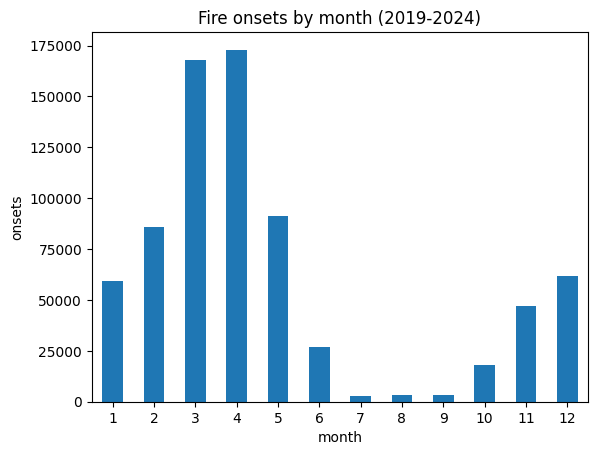

In [7]:
bw.cell_day_overview()

**Labelled rows.** Each onset (label 1) is matched with 20 negatives (label 0): same state and year, an in-season day, and no detection in the 3 days before. This is why only about 1 in 21 rows is positive.

In [8]:
bw.labelled_rows_overview()

,cell,day,label,kind,state,year,group,band
928445,32186,17961,1,onset,CG,2019,train,A
928446,32186,17968,1,onset,CG,2019,train,A
928447,32186,17979,1,onset,CG,2019,train,A
928448,32186,17985,1,onset,CG,2019,train,A
928449,32186,17991,1,onset,CG,2019,train,A


,rows,onsets,share_positive
year,,,
2019,1100358,52398,0.047619
2020,820932,39092,0.047619
2021,1564143,74483,0.047619
2022,1280118,60958,0.047619
2023,1435833,68373,0.047619
2024,1148847,54707,0.047619


## 2. Model inputs

The dataset is built by the project: the model table (one row per labelled cell-day) plus two memory-mapped arrays of the enriched level. Rows with any missing input are marked incomplete and are not used, as in the official pipeline.

In [9]:
display(w.load())

6,880,578 labelled rows; 6,841,251 complete (99.4%)
inputs: 42 tabular + 209 enriched = 251 columns at the enriched level


,cell,day,year,state,label,t2m,vpd,ws,rh,sw1,sw2,rain7,dsr
0,32186,17961,2019,CG,1,31.824808,2.474823,5.454613,47.432621,0.254654,0.293625,2.117210,36.0
1,32186,17968,2019,CG,1,32.975975,3.067967,8.494343,38.926159,0.248528,0.287674,0.052998,43.0
2,32186,17979,2019,CG,1,35.545021,3.700998,1.600075,36.126766,0.248428,0.282516,0.264756,54.0
3,32186,17985,2019,CG,1,36.243553,4.133716,4.155025,31.343313,0.247551,0.280952,0.007772,60.0
4,32186,17991,2019,CG,1,36.603661,4.261005,9.808577,30.609486,0.248474,0.279984,0.667781,60.0


**The enriched level.** Past weather in windows of 3 to 60 days (mean and max), anomalies against the day-of-year norm, and the neighbouring cells. They are stored in arrays on disk and read in blocks.

In [10]:
w.enriched_examples()

weather windows array: (6880578, 180) | neighbourhood array: (6880578, 12)


,t2m_mean3,t2m_max3,t2m_mean7,t2m_max7,t2m_mean14,t2m_max14
0,31.176577,32.038551,30.609264,32.038551,31.700617,34.366325
1,33.606544,34.941628,33.311790,34.941628,31.960527,34.941628
2,33.931206,35.545021,33.394169,35.545021,33.750195,35.545021
3,36.008446,36.279686,36.089001,36.470634,34.684502,36.470634
4,37.077171,37.413841,37.272453,38.116570,36.467335,38.116570


,ring_8_tree_cover,ring_8_burn_count,ring_8_years_since_burn,ring_8_vegetation_index,ring_8_fire_weather_index,ring_8_onsets_recent,ring_24_tree_cover,ring_24_burn_count,ring_24_years_since_burn,ring_24_vegetation_index,ring_24_fire_weather_index,ring_24_onsets_recent
0,0.703,2.302,1.010,0.531,24.921000,0.0,0.761,2.309,1.792,0.552,25.000999,0.0
1,0.703,2.302,1.029,0.492,37.419998,2.0,0.761,2.307,1.810,0.512,37.493000,7.0
2,0.703,2.302,1.060,0.401,30.087000,8.0,0.761,2.307,1.837,0.419,30.180000,28.0
3,0.703,2.315,0.828,0.401,37.257999,14.0,0.761,2.318,1.637,0.419,37.297001,43.0
4,0.703,2.315,0.844,0.352,49.808998,16.0,0.761,2.325,1.650,0.370,49.967999,49.0


**Do the inputs separate fires from non-fires?** Distributions for onset days (1) and matched negatives (0).

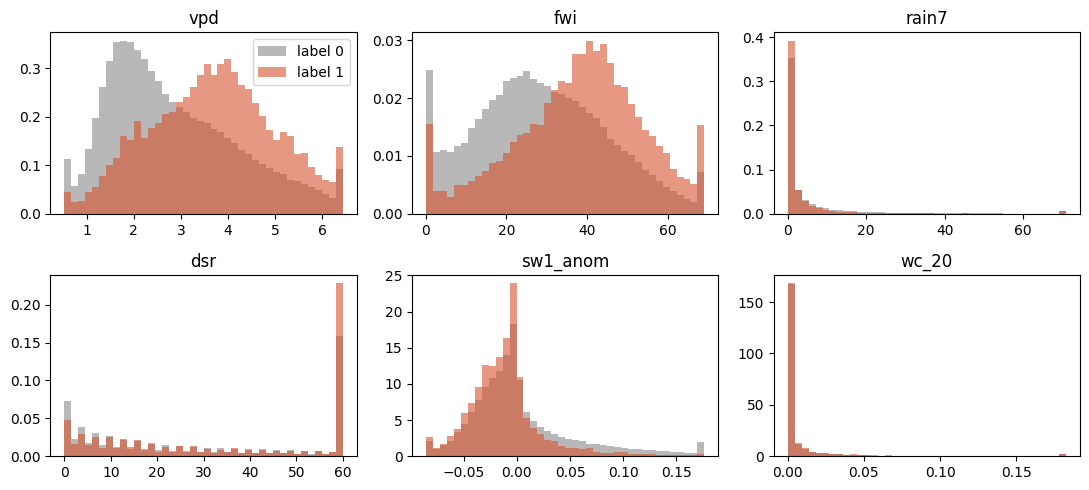

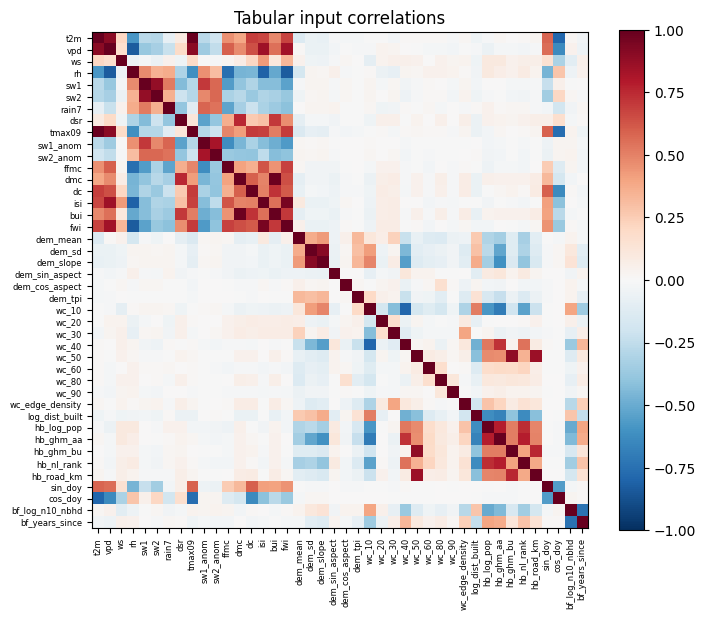

In [11]:
w.plot_distributions()
w.plot_correlations()

**The split, as the official rolling-origin fold builds it.** Fit on every complete row of the years before the test year (thinned to the fit-row cap, all onsets kept); evaluate on the January-July rows of the test year. The last fit year doubles as the network's early-stopping set. Each row carries a **design weight**: an onset counts 1, a sampled negative counts for the many cell-days it stands in for, so weighted results describe the real world, not the 1-in-21 sample.

In [12]:
w.make_split()

,rows,onsets,years,share positive
fit,2000000,237416,2019-2023,0.1187
test,726279,37679,2024 (Jan-Jul),0.0519


,mean design weight
negative rows,8.91
onset rows,1.00


## 3. The one best setting per model

Only the tuned setting is used below. Logistic regression has one fixed setting (C = 0.01).

{
 "boosting": {
  "max_depth": 8,
  "learning_rate": 0.05,
  "max_iter": 500,
  "l2_regularization": 0,
  "min_samples_leaf": 100
 },
 "network": {
  "width": 256,
  "depth": 2,
  "dropout": 0.1,
  "learning_rate": 0.0003,
  "weight_decay": 0.0001
 }
}


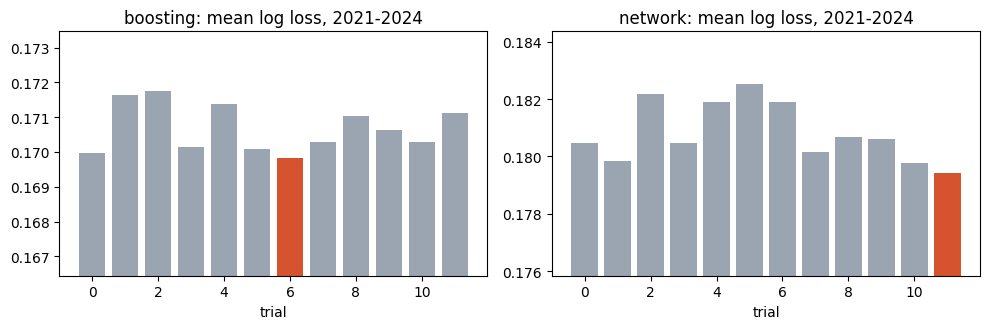

In [13]:
w.plot_tuning()

## 4. Models

Each model is fitted with the project's own classes and the official steps, keeping the fitted object so it can also predict the training rows.

**Logistic regression**, the simple linear baseline the stronger models must beat.

In [14]:
w.fit_logistic()

/Users/kireeti/wildfire/.venv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


logistic {'C': 0.01} | inputs: 251


**Boosted trees** with the tuned setting. The curve shows log loss as trees are added; a validation curve that turns upward would mean overfitting.

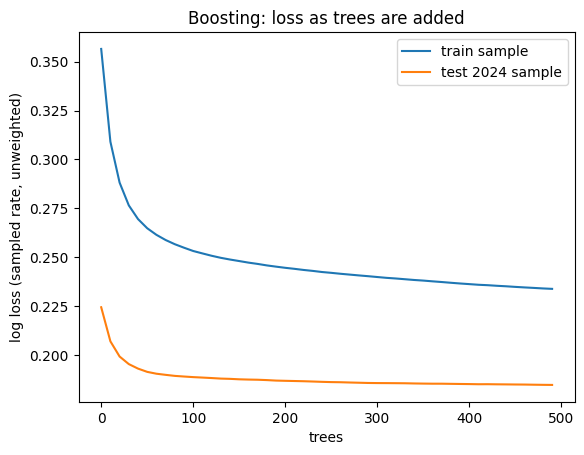

In [15]:
w.fit_boosting()
w.plot_boosting_curve()

**Neural network (PyTorch)**, the project's `Network` with its tuned setting. The per-epoch history comes from a thin subclass of the official class (`wildfire.models.network_traced`); its predictions must equal the official ones, which section 6 checks.

,epoch,train_loss,stop_year_loss
0,1,0.0629,0.0760
1,2,0.0614,0.0748
2,3,0.0605,0.0741
3,4,0.0599,0.0735
4,5,0.0595,0.0734
5,6,0.0592,0.0735
6,7,0.0589,0.0733
7,8,0.0586,0.0729
8,9,0.0583,0.0730
9,10,0.0582,0.0733


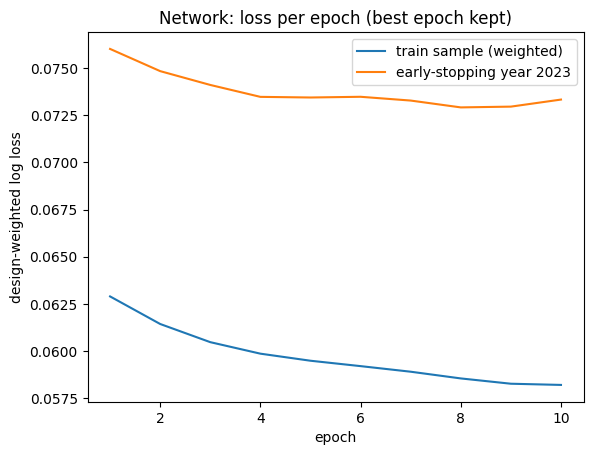

In [16]:
display(w.fit_network())
w.plot_network_curve()

## 5. Official results: the whole ladder

The saved rolling-origin predictions of **every** arm, scored with the official functions (design weights, prior-shift-corrected log loss and Brier, both AUC views, AP, top-k). Network rows are the mean over the 10 seeds.

In [17]:
display(w.official_ladder())

,ap,auc_spatial_within_day,auc_temporal_within_cell,log_loss,brier,capture_5pct,lift_5pct
model,,,,,,,
climatology_cell,0.1059,0.6826,0.6265,0.0724,0.0143,0.1960,3.9194
landcover_season,0.0919,0.5561,0.7097,0.0743,0.0144,0.0954,1.9088
fwi_season,0.0997,0.5641,0.7191,0.0731,0.0143,0.1263,2.5255
logistic_weather_static@tabular,0.1177,0.6183,0.7367,0.0717,0.0143,0.1483,2.9666
logistic_weather_static@enriched,0.1782,0.7421,0.7701,0.0678,0.0143,0.2238,4.4752
logistic_with_burn@tabular,0.1270,0.6368,0.7352,0.0712,0.0143,0.1672,3.3440
logistic_with_burn@enriched,0.1788,0.7425,0.7701,0.0678,0.0143,0.2243,4.4868
boosting@tabular,0.1988,0.7748,0.7724,0.0665,0.0140,0.2352,4.7045
boosting@enriched,0.2471,0.8169,0.7958,0.0635,0.0138,0.2835,5.6705


**Validation year by year.** The same models fitted on the earlier years and scored on each next year. A steady gap between models in every year is more convincing than one good year.

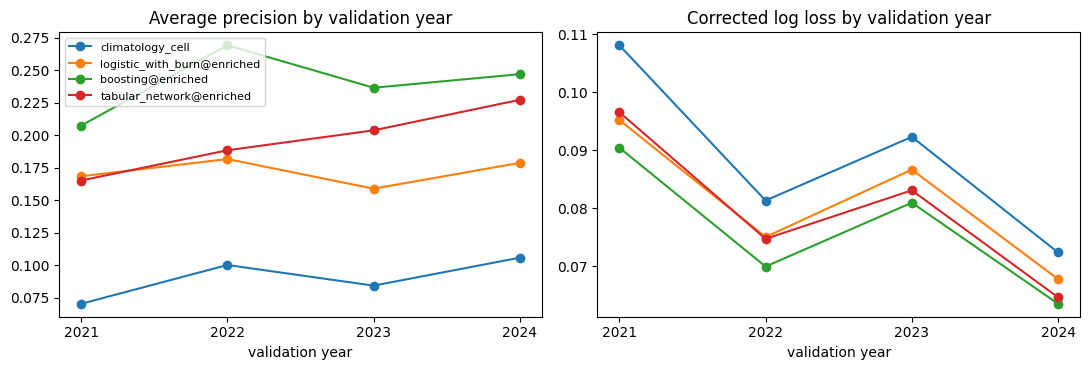

In [18]:
w.plot_by_year()

## 6. Training, validation and test

Three splits: **train** is a sample of this fold's own fit rows (it measures memorisation), **validation** is the official held-out fold of the year before, **test** is the official held-out fold of the test year. Models: logistic regression, boosting and the network (seed 0).

**Official metrics** first (log loss and Brier on corrected probabilities, AP and AUC on the raw scores, all with the official functions).

In [19]:
w.compare()
display(w.show_official_metrics())

OFFICIAL functions (design-weighted, prior-shift-corrected log loss and Brier; AP and AUC on the raw scores).
The train rows are a sample of this fold's own fit rows and are not part of the official tables.


log_loss   brier      ap     auc
model    split                                  
logistic train    0.0666  0.0142  0.3904  0.8139
         val      0.0867  0.0185  0.1590  0.7604
         test     0.0678  0.0143  0.1788  0.7936
boosting train    0.0589  0.0133  0.5482  0.8762
         val      0.0810  0.0177  0.2366  0.8089
         test     0.0635  0.0138  0.2471  0.8349
network  train    0.0618  0.0137  0.4789  0.8509
         val      0.0833  0.0183  0.2042  0.7984
         test     0.0646  0.0139  0.2294  0.8214

**Not official: thresholded metrics.** Accuracy, precision, recall and F1 need a yes/no decision, so they use one threshold per model: the corrected probability that maximises weighted F1 on the held-out validation year. The same threshold is applied to train, validation and test, so the test year never picks it. They use the design weights, so they describe real cell-days: fires are rare, so accuracy is high even for a model that never predicts a fire, and precision is low. Compare accuracy with the always-no value.

In [20]:
display(w.show_extra_metrics())

NOT OFFICIAL: thresholded metrics added for this notebook. Threshold per model (corrected probability, chosen on validation): {'logistic': 0.05, 'boosting': 0.0801, 'network': 0.0962}
Weighted accuracy of always saying 'no fire': {'train': 0.985, 'val': 0.9808, 'test': 0.9853}


accuracy  balanced_accuracy  precision  recall      f1
model    split                                                        
logistic train    0.9410             0.6404     0.0920  0.3305  0.1440
         val      0.9368             0.5932     0.0855  0.2359  0.1255
         test     0.9347             0.6235     0.0746  0.3029  0.1197
boosting train    0.9657             0.6517     0.1690  0.3281  0.2231
         val      0.9512             0.5971     0.1146  0.2289  0.1527
         test     0.9643             0.5985     0.1180  0.2217  0.1540
network  train    0.9671             0.6216     0.1542  0.2655  0.1951
         val      0.9465             0.6047     0.1092  0.2492  0.1519
         test     0.9682             0.5817     0.1196  0.1836  0.1448

**Train versus test.** A big gap means the model has memorised the training years. The first three panels are official metrics; the last three are not official.

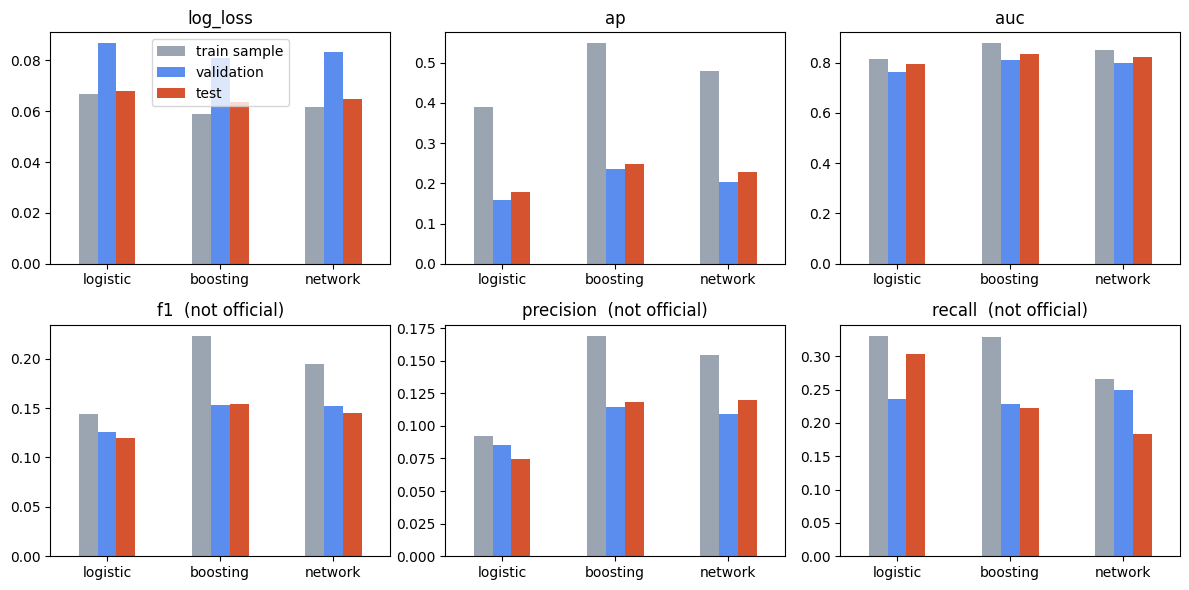

,train - test log loss,train - test AP,train - test F1 (not official)
model,,,
logistic,-0.0012,0.2116,0.0243
boosting,-0.0046,0.3012,0.0691
network,-0.0028,0.2495,0.0502


In [21]:
display(w.plot_train_val_test())

**Ranking and probability quality on the test year** (official ROC, precision-recall and the official reliability table).

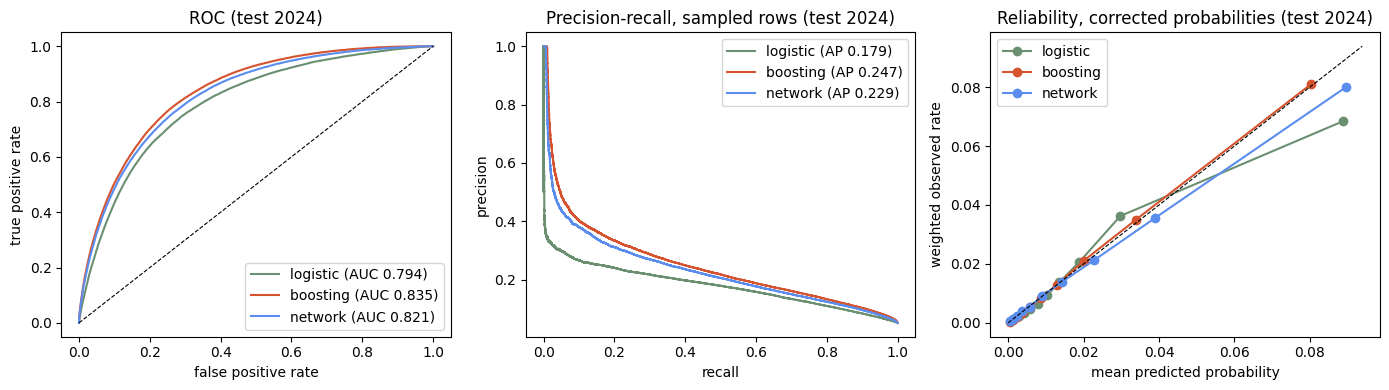

In [22]:
w.plot_curves()

**Not official: confusion matrices** on the test year, design-weighted, as the share of each true class predicted fire or no fire.

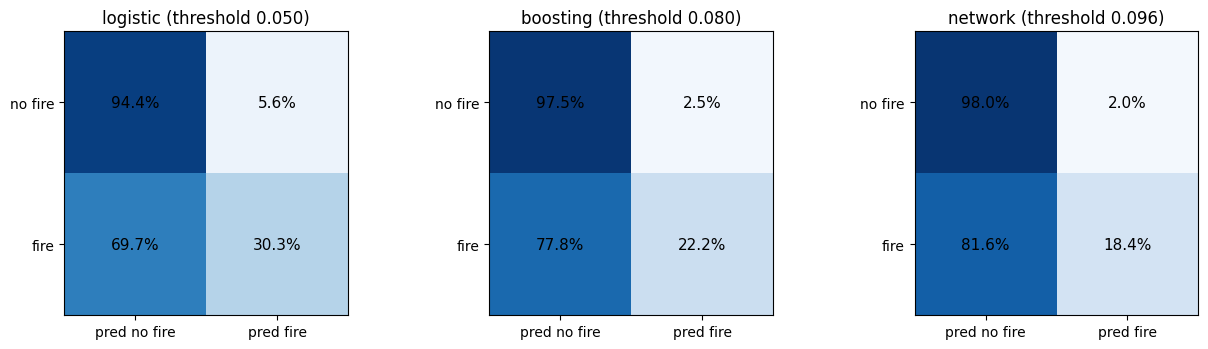

In [23]:
w.plot_confusion()

**How many fires are caught by looking at only the top-scored rows** (test year, official top-k capture and lift).

In [24]:
display(w.topk_table())

,capture_1pct,lift_1pct,capture_5pct,lift_5pct,capture_10pct,lift_10pct
logistic,0.057,5.693,0.224,4.487,0.385,3.855
boosting,0.082,8.198,0.284,5.671,0.450,4.495
network,0.077,7.728,0.270,5.407,0.434,4.343


**Not official: what the boosting model relies on.** Block permutation on a test sample: how much the average precision drops when one tabular input (or a whole enriched block) is shuffled.

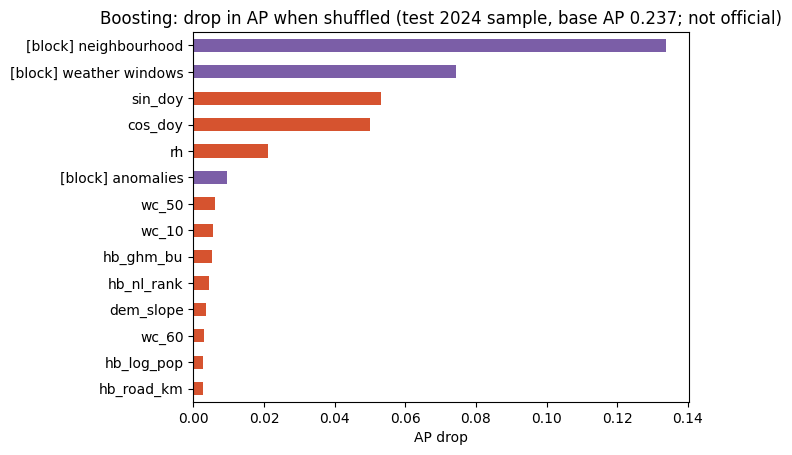

In [25]:
w.plot_importance()

**Does the refit match the official run?** The saved official predictions for the test year against the predictions of the models fitted above. Identical numbers mean this notebook follows the official pipeline step for step.

In [26]:
display(w.match_check())

,model,rows,max_abs_diff,identical,fit_prevalence_saved,fit_prevalence_refit
0,logistic,726279,0.0,True,0.118708,0.118708
1,boosting,726279,0.0,True,0.118708,0.118708
2,network,726279,0.0,True,0.014323,0.014323


## 7. Summary

In [27]:
w.summary()

Test 2024: lowest corrected log loss is boosting (0.0635).
Test AP: logistic 0.179, boosting 0.247, network 0.229
NOT OFFICIAL, test F1 / precision / recall: logistic 0.120 / 0.075 / 0.303; boosting 0.154 / 0.118 / 0.222; network 0.145 / 0.120 / 0.184
NOT OFFICIAL, test accuracy: logistic 0.9347, boosting 0.9643, network 0.9682 (always 'no fire': 0.9853).
Train - test log loss: logistic -0.0012, boosting -0.0046, network -0.0028 (negative = better on train).


**Limits.** The 2024 test year helped choose the settings; the untouched checks (2025, the fresh states, the 2026 season) are scored by the official pipeline. Accuracy, precision, recall, F1, the confusion matrices, the importance chart and the training-set rows are not part of the official tables. Network rows here are seed 0; the official table averages 10 seeds. Training-set rows use the per-state onset rate before the test year as the "true" rate for the prior-shift correction. Thresholded metrics depend on a threshold chosen on one validation year.